# Heart Disease Classification

Comparison of 7 classification and clustering models on the Heart Disease dataset (303 patients, 13 clinical features).
In this Kaggle version `output = 1` corresponds to no disease and `output = 0` to disease (see the README).

The same models are served in an interactive Gradio app (`app.py`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from statistics import mode

df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [2]:
# Eliminamos duplicados
df.drop_duplicates(keep='first', inplace=True)
df.shape

(302, 14)

# Train / test split

The split is done **before** scaling, so the scaler only learns from the training data (no data leakage).

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

y = df['output']
X = df.drop(['output'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
    )

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

results = {}
predictions = {}

def evaluate(name, y_pred):
    predictions[name] = np.array(y_pred)
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
    }
    for metric, value in results[name].items():
        print(f'{metric}: {value:.3f}')

Clustering models (KMeans and Fuzzy c-means) return cluster ids, not classes.
Each cluster is mapped to the most common class of the training points it contains.

In [5]:
def cluster_to_class(train_clusters, y_train):
    mapping = {}
    for c in np.unique(train_clusters):
        mapping[c] = y_train[train_clusters == c].mode()[0]
    return mapping

# Logistic Regression

In [6]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

evaluate('Logistic Regression', log_reg.predict(X_test))

Accuracy: 0.787
Precision: 0.763
Recall: 0.879
F1 Score: 0.817


# Fuzzy c-means

In [7]:
import skfuzzy as fuzz

cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(X_train.T, 2, 2, error=0.005, maxiter=1000, seed=42)

fuzzy_map = cluster_to_class(np.argmax(u, axis=0), y_train)

u, u0, d, jm, p, fpc = fuzz.cluster.cmeans_predict(X_test.T, cntr, 2, error=0.005, maxiter=1000, seed=42)
y_pred = [fuzzy_map[c] for c in np.argmax(u, axis=0)]

evaluate('Fuzzy c-means', y_pred)

Accuracy: 0.721
Precision: 0.735
Recall: 0.758
F1 Score: 0.746


# KMeans

In [8]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_train)

kmeans_map = cluster_to_class(kmeans.labels_, y_train)
y_pred = [kmeans_map[c] for c in kmeans.predict(X_test)]

evaluate('KMeans', y_pred)

Accuracy: 0.770
Precision: 0.721
Recall: 0.939
F1 Score: 0.816


# KNN

In [9]:
from sklearn.neighbors import KNeighborsClassifier

neigh = KNeighborsClassifier(n_neighbors=2)
neigh.fit(X_train, y_train)

evaluate('KNN', neigh.predict(X_test))

Accuracy: 0.738
Precision: 0.815
Recall: 0.667
F1 Score: 0.733


# Decision Trees

In [10]:
from sklearn.tree import DecisionTreeClassifier

## Criterion: entropy or gini
tree = DecisionTreeClassifier(max_depth=5, criterion='entropy', random_state=42)
tree.fit(X_train, y_train)

evaluate('Decision Tree', tree.predict(X_test))

Accuracy: 0.836
Precision: 0.780
Recall: 0.970
F1 Score: 0.865


# Naive Bayes

In [11]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)

evaluate('Naive Bayes', nb.predict(X_test))

Accuracy: 0.820
Precision: 0.789
Recall: 0.909
F1 Score: 0.845


# Random Forest

In [12]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(max_depth=10, random_state=42)
forest.fit(X_train, y_train)

evaluate('Random Forest', forest.predict(X_test))

Accuracy: 0.803
Precision: 0.769
Recall: 0.909
F1 Score: 0.833


# All together

Majority vote of the 7 models.

In [13]:
votes = np.array(list(predictions.values()))
y_pred = [mode(votes[:, i]) for i in range(votes.shape[1])]

evaluate('Majority vote', y_pred)

Accuracy: 0.787
Precision: 0.750
Recall: 0.909
F1 Score: 0.822


In [14]:
pd.DataFrame(results).T.round(3)

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.787,0.763,0.879,0.817
Fuzzy c-means,0.721,0.735,0.758,0.746
KMeans,0.770,0.721,0.939,0.816
KNN,0.738,0.815,0.667,0.733
Decision Tree,0.836,0.780,0.970,0.865
Naive Bayes,0.820,0.789,0.909,0.845
Random Forest,0.803,0.769,0.909,0.833
Majority vote,0.787,0.750,0.909,0.822


# Plot

2D projections of the standardized data, colored by class.

In [15]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from umap import validation

X_std = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

tsne = TSNE(n_components=2, init='pca', random_state=42)
X_tsne = tsne.fit_transform(X_std)

reducer = UMAP(random_state=42)
X_umap = reducer.fit_transform(X_std)

trust = validation.trustworthiness_vector(source=X_std, embedding=X_umap, max_k=30)

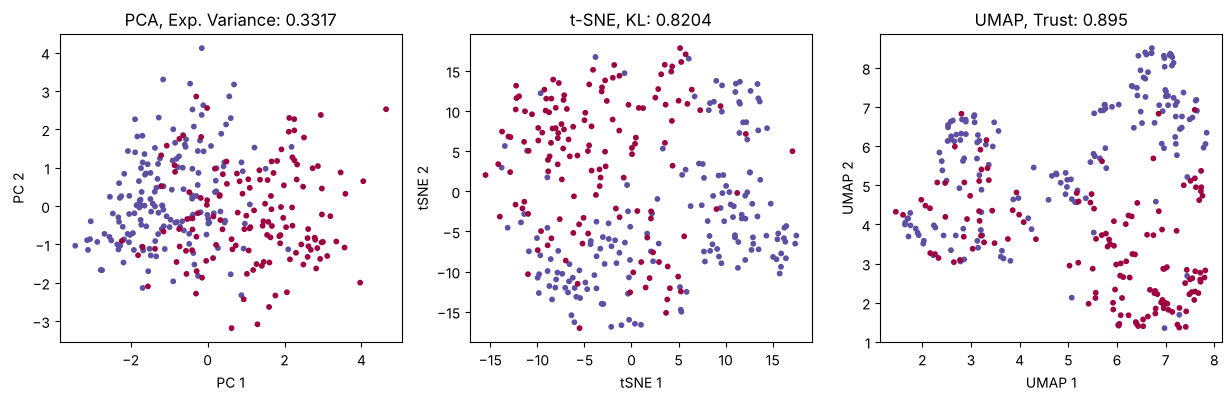

In [16]:
fig = plt.figure(figsize=(15,4))

# PCA
plt.subplot(131)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap=plt.cm.Spectral, s=10)
plt.title(f"PCA, Exp. Variance: {np.round(np.sum(pca.explained_variance_ratio_), 4)}")
plt.xlabel("PC 1")
plt.ylabel("PC 2")

# t-SNE
plt.subplot(132)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap=plt.cm.Spectral, s=10)
plt.title(f"t-SNE, KL: {np.round(tsne.kl_divergence_, 4)}")
plt.xlabel("tSNE 1")
plt.ylabel("tSNE 2")

# UMAP
plt.subplot(133)
plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap=plt.cm.Spectral, s=10)
plt.title(f"UMAP, Trust: {np.round(trust[1:].mean(), 4)}")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.show();